# Instalar mi paquete

In [ ]:
%pip install -q "git+https://github.com/adbaldel/Complex-Dynamics-Thesis.git"

In [ ]:
%pip install -q --upgrade "IPython>=9.17" "pyvista>=0.48.4"

# Dinámica de $R(z)=z+\frac{1}{z}$

Estudiamos esta aplicación racional de grado $2$ en la esfera de Riemann. El análisis combina identidades exactas, órbitas numéricas y una aproximación de tiempo finito. En particular, una salida de un disco no debe confundirse automáticamente con convergencia a infinito.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

import complex_dynamics.calculator as dcalc
import complex_dynamics.plot as dplot
from complex_dynamics.rational_map import RationalMap

plt.style.use(
    "https://raw.githubusercontent.com/adbaldel/Complex-Dynamics-Thesis/main/code/notebooks/report.mplstyle"
)


## Datos algebraicos

Escribimos

$$R(z)=\frac{z^2+1}{z}.$$

El único polo finito es $0$, que se envía a infinito. No hay puntos fijos finitos porque $R(z)=z$ exigiría $1/z=0$. El punto $\infty$ sí es fijo.

Los puntos críticos finitos satisfacen

$$R'(z)=1-\frac{1}{z^2}=0,$$

por lo que son $z=\pm1$.

In [5]:
R = RationalMap([1, 0, 1], [0, 1])

print(f"R(z) = {R}")
print(f"degree = {R.degree}")
print(f"poles = {R.poles(include_infinity=False)}")
print(f"zeros = {R.roots(include_infinity=False)}")
print(
    f"finite critical points = {R.derivative().roots(include_infinity=False)}"
)


R(z) = \frac{z^{2} + 1}{z}
degree = 2
poles = [0.+0.j]
zeros = [0.00000000e+00+1.j 2.77555756e-17-1.j]
finite critical points = [-1.+0.j  1.+0.j]


## El punto fijo en infinito es parabólico

Para clasificar un punto fijo en infinito hay que usar la coordenada local $w=1/z$, no la derivada afín de `R`. La aplicación conjugada es

$$G(w)=\frac{1}{R(1/w)}=\frac{w}{1+w^2}=w-w^3+O(w^5).$$

Por tanto, $G(0)=0$ y $G'(0)=1$: infinito es un punto fijo **parabólico**. La conjugación también permite estudiar la misma dinámica cerca de $0$.

In [6]:
G = RationalMap([0, 1], [1, 0, 1])
sample = np.array([0.7 + 0.4j, -1.2 + 0.3j], dtype=np.complex128)

conjugacy_error = np.max(np.abs(1 / R(sample) - G(1 / sample)))
print(f"G(w) = {G}")
print(f"maximum conjugacy error = {conjugacy_error:.3e}")


G(w) = \frac{z}{z^{2} + 1}
maximum conjugacy error = 1.186e-16


## Semiplanos invariantes y conjunto de Julia

Si $z=x+iy\ne0$, entonces

$$\operatorname{Re}R(z)=x\left(1+\frac{1}{|z|^2}\right).$$

En consecuencia, el signo de la parte real se conserva y $|\operatorname{Re}z_n|$ crece estrictamente fuera del eje imaginario. De hecho, los puntos del semiplano derecho convergen a infinito desde la derecha y los del izquierdo desde la izquierda.

El eje imaginario, junto con infinito, es la frontera común de esos dos dominios parabólicos y es

$$J(R)=i\mathbb{R}\cup\{\infty\}.$$

El eje es completamente invariante. Sus puntos no «escapan» de manera monótona: pueden realizar excursiones muy grandes y regresar cerca del origen, donde el polo vuelve a producir una imagen grande.

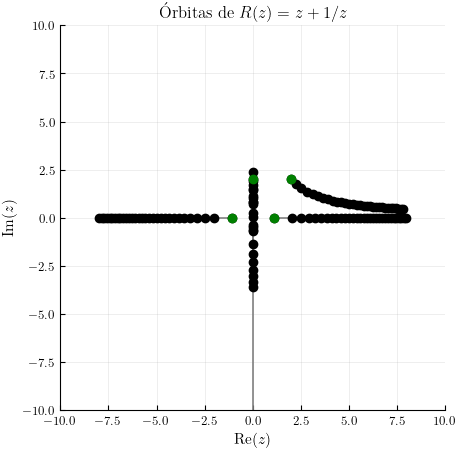

In [7]:
initial_points = np.array([1.1, -1.1, 2j, 2 + 2j], dtype=np.complex128)
max_iterations = 30
orbits = dcalc.calculate_forward_orbit(
    initial_points, R, max_iterations=max_iterations
)

fig, ax = dplot.plot_orbits(orbits)
ax.set_title(r"Órbitas de $R(z)=z+1/z$")
ax.set_xlabel(r"$\operatorname{Re}(z)$")
ax.set_ylabel(r"$\operatorname{Im}(z)$")
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_aspect("equal")
ax.grid(True)


First iterates on the invariant imaginary axis:
 0:  0+2j
 1:  0+1.5j
 2:  0+0.83333333j
 3:  0-0.36666667j
 4: -0+2.3606061j
 5:  0+1.936986j
 6:  0+1.4207201j
 7:  0+0.71685162j
 8:  0-0.67813722j
 9: -0+0.79649059j


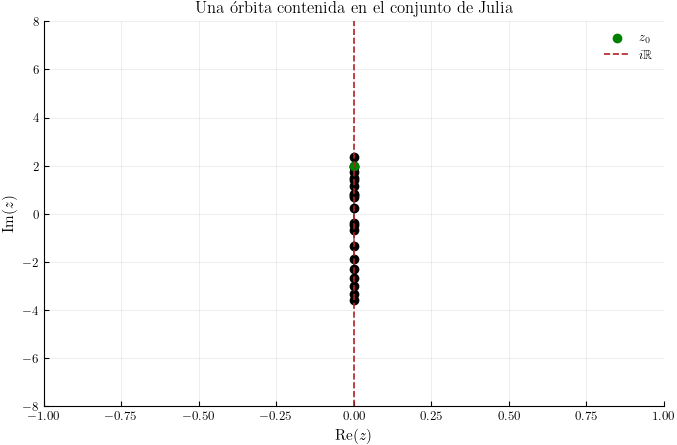

In [8]:
imaginary_seed = np.complex128(2j)
imaginary_orbit = dcalc.calculate_forward_orbit(
    imaginary_seed, R, max_iterations=20
)

print("First iterates on the invariant imaginary axis:")
for index, value in enumerate(imaginary_orbit[:10]):
    print(f"{index:2d}: {value: .8g}")

fig, ax = dplot.plot_orbit(imaginary_orbit)
ax.axvline(0, color="firebrick", linestyle="--", label=r"$i\mathbb{R}$")
ax.set_title("Una órbita contenida en el conjunto de Julia")
ax.set_xlabel(r"$\operatorname{Re}(z)$")
ax.set_ylabel(r"$\operatorname{Im}(z)$")
ax.set_xlim(-1, 1)
ax.set_ylim(-8, 8)
ax.legend()


## Diagnóstico de primera salida

La siguiente imagen cuenta la primera salida del disco $|z|<8$. Es útil para visualizar el tránsito lento hacia el punto parabólico, pero **no** certifica divergencia para esta aplicación racional. En particular, puntos del eje imaginario pueden salir del disco y volver.

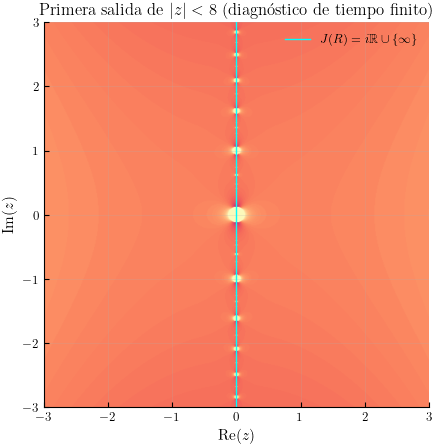

In [9]:
extent = [-3.0, 3.0, -3.0, 3.0]
mesh = dcalc.create_mesh(*extent, xpixels=500, ypixels=500)
max_iterations = 120
first_exit_times = dcalc.calculate_divergence_times(
    mesh, R, max_iterations=max_iterations, escape_radius=8
)

fig, ax = dplot.plot_divergence_times(
    first_exit_times,
    max_iterations=max_iterations,
    extent=extent,
    cmap="magma_r",
)
ax.axvline(
    0, color="cyan", linewidth=1, label=r"$J(R)=i\mathbb{R}\cup\{\infty\}$"
)
ax.set_title("Primera salida de $|z|<8$ (diagnóstico de tiempo finito)")
ax.set_xlabel(r"$\operatorname{Re}(z)$")
ax.set_ylabel(r"$\operatorname{Im}(z)$")
ax.set_aspect("equal")
ax.legend()


## Órbitas hacia atrás

Resolver $R(z)=w$ da

$$z=\frac{w\pm\sqrt{w^2-4}}{2}.$$

Partiendo del polo $0$ y tomando repetidamente ambas ramas obtenemos preimágenes contenidas en el eje imaginario. La órbita hacia atrás de un punto no excepcional del Julia es densa en el conjunto de Julia; el dibujo proporciona otra aproximación, ahora independiente de un radio de escape.

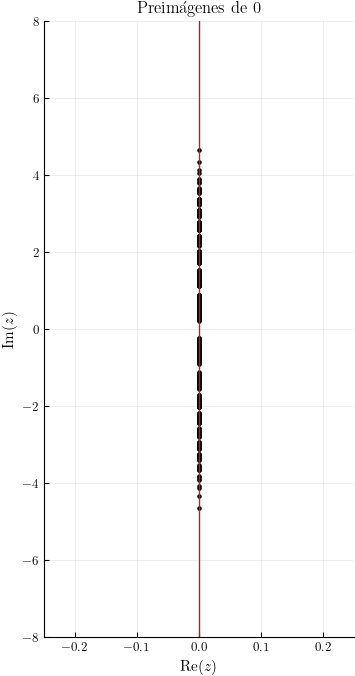

In [10]:
def backward_preimages(targets: np.ndarray, depth: int) -> np.ndarray:
    values = np.asarray(targets, dtype=np.complex128)
    for _ in range(depth):
        root = np.sqrt(values**2 - 4)
        values = np.concatenate(((values + root) / 2, (values - root) / 2))
    return values


preimages = backward_preimages(np.array([0j]), depth=12)

fig, ax = plt.subplots(figsize=(4, 8))
ax.scatter(preimages.real, preimages.imag, s=5, color="black")
ax.axvline(0, color="firebrick", linewidth=1)
ax.set_xlim(-0.25, 0.25)
ax.set_ylim(-8, 8)
ax.set_title("Preimágenes de 0")
ax.set_xlabel(r"$\operatorname{Re}(z)$")
ax.set_ylabel(r"$\operatorname{Im}(z)$")
ax.grid(True)


## Conclusión

La dinámica tiene dos dominios parabólicos invariantes, los semiplanos derecho e izquierdo, que convergen al mismo punto fijo $\infty$. Su frontera común es el eje imaginario completo en la esfera. La conjugada $w/(1+w^2)$ intercambia el estudio de infinito por el del punto parabólico $0$ sin alterar esta estructura dinámica.